## Single-column RCE model

This notebook contains the structure for your RCE model. There are key functions to complete and all visulizations are left to your design.

This RCE model will follow the Manabe and Strickler 1964 approach.

In [626]:
import numpy as np 
import matplotlib.pyplot as plt
import os
env = r"C:\Users\cox0367\AppData\Local\miniforge3\envs\atmos"
os.environ["PATH"] = ";".join([
    env, env + r"\Library\mingw-w64\bin", env + r"\Library\usr\bin",
    env + r"\Library\bin", env + r"\Scripts"
]) + ";" + os.environ["PATH"]


def moist_adiabat(P, T):   
    Lv = 2.5*10**6
    T = T+273.15
    es = 6.112*np.exp(17.67*(T-273.15)/(T-29.65)) 
    eps = 0.622 
    rs = eps*es/(P-es)   
    num = 1+ (Lv*rs)/(Rd*T)
    denom = 1+(Lv**2*rs)/(1004*461*T**2)
    slope = 9.81/1004*(num)/denom *287*T/P/9.81
    return slope 

def dry_adiabat(P, T): return Rd*(T+273.15)/(P)/1004

#### Main settings and parameters

In [627]:
# Experiment selection:
# 'convective_mode_variation' runs the sweep of equilibrium modes
# 'tau0_variation' runs a sweep of surface optical thickness values (tau0)
select_experiment = 'convective_mode_variation'

# Experiment-dependent settings:
convective_mode_sweep = ["radiative", "dry", "moist"] # the three equilibrium modes to sweep over
#convective_mode_sweep = ["radiative"] # the three equilibrium modes to sweep over
tau0_sweep = [0.1, 1, 2, 4, 6] # surface optical depth values to sweep over

#### Parameters

In [628]:
# Physical constants
g = 9.81                  # m/s^2
Rd = 287.0                # J/(kg K)
Rv = 461.0                # J/(kg K)
cp = 1004.0               # J/(kg K)
Lv = 2.5e6                # J/kg
sigma = 5.670374419e-8    # Stefan-Boltzmann
CtoK = 273.15             # Celsius to Kelvin

# Model parameters
Nz = 60                   # number of atmospheric layers
p_surf = 100000.0         # Pa
p_top  = 5000.0           # Pa
dt = 1000.0               # time step (s)
max_iter = 50000          # maximum number of iterations
T0_init = 250.0           # initial isothermal temperature profile (K)

# Radiative transfer settings
S0 = 1361.0                     # solar constant (W/m2)
albedo = 0.3                    # planetary albedo
S_in = S0 * (1 - albedo) / 4.0  # incoming solar radiation at TOA (W/m2)
relh0 = 0.8                     # assumed constant relative humidity for moist convective mixing
tau0 = 4.0                      # optical thickness at surface (tau(p_surf) = tau0)
tau_n = 2.0                     # exponent for tau(p) = tau0 * (p/p0)^n
mu_bar = 0.6                    # diffusivity factor for conversion from I to F

#### Helper functions

##### Create vertical grid

In [629]:
'''
This function sets up the vertical grid and initial T-profile for the RCE model.

Its structure is as follows:

             TOP
        -------------------  p_edges[Nz] = p_top
             p_mid[Nz-1]     layer Nz-1
        -------------------  p_edges[Nz-1]
               ...
        -------------------  p_edges[2]
             p_mid[1]        layer 1
        -------------------  p_edges[1]
             p_mid[0]        layer 0
        -------------------  p_edges[0] = p_surf
            SURFACE

Index increases upward; pressure decreases upward.
Grid spacing is uniform in pressure.

Temperature is defined at layer midpoints.
Optical depth tau is defined at edges and decreases upward
(assuming tau0 > 0 and tau_n > 0).

For each layer k:
  p_mid[k] = 0.5 * (p_edges[k] + p_edges[k+1])
  dp[k]    = p_edges[k] - p_edges[k+1] > 0
  dtau[k]  = tau_edges[k] - tau_edges[k+1] > 0

'''
def get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init):

    # Vertical grid (pressure edges and midpoints)
    p_edges = np.linspace(p_surf, p_top, Nz+1)    # edges (Pa), bottom --> top
    p_mid = 0.5*(p_edges[:-1] + p_edges[1:])      # pressure at layer mid-points
    dp = p_edges[:-1] - p_edges[1:]               # dp of each layer (positive)

    # Optical depth at layer edges
    tau_edges = tau0 * (p_edges / p_surf)**tau_n
    dtau = tau_edges[:-1] - tau_edges[1:]

    # Initial isothermal temperature profile (defined at layer midpoints)
    T_init = np.repeat(T0_init, Nz) # K

    grid = {}
    grid['p_edges'] = p_edges
    grid['p_mid'] = p_mid
    grid['dp'] = dp
    grid['tau_edges'] = tau_edges
    grid['dtau'] = dtau
    grid['T_init'] = T_init

    return grid

##### Thermodynamic functions

In [630]:
# saturation vapor pressure (Magnus)
def es_sat(Tk):
    Tc = Tk - 273.15
    return 610.94 * np.exp(17.625 * Tc / (Tc + 243.04))

# saturation mixing ratio from saturation vapor pressure
def qsat(Tk, p):
    eps = Rd / Rv
    e_s = es_sat(Tk)
    return eps * e_s / (p - (1-eps)*e_s)

def moist_lapse_rate_K_per_m(DALR, Tk, p, RH=1.0):
    """
    Moist-adiabatic lapse rate with saturation mixing ratio scaled by a given RH.
    DALR input is the dry adiabatic lapse rate, provided either in K/m or K/Pa,
    which determines the units of the returned lapse rate.
    """
    q = qsat(Tk, p) * RH
    numerator = DALR * (1.0 + (Lv * q) / (Rd * Tk))
    denominator = 1.0 + (Lv**2 * q) / (cp * Rv * Tk**2)
    return numerator / denominator

##### Radiative tranfer

In [631]:
def longwave_fluxes_and_heating(T,Nz,S_in, sigma,mu_bar,grid):
    """

    Your function should conduct downward and upward flux sweeps and return the
    downward (F_down) and upward (F_up) fluxes at the layer edges, which you can
    then use to compute the net flux and heating rate for each layer.

    """ 
    dtau = grid['dtau'] 
    F_up = np.zeros(Nz+1)
    F_down = np.zeros(Nz+1)

    Tr = np.exp(-dtau/mu_bar) 
    eps = 1-Tr

    #for i in range(Nz): 
    #    F_down[-i-2] = F_down[-i-1]* Tr[-i-2] +eps[-i-2]*sigma*T[-i-1]**4
    for i in range(Nz): 
        F_down[Nz-i-1] = F_down[Nz-i]* Tr[Nz-i-1] +eps[Nz-i-1]*sigma*T[Nz-i-1]**4
    F_up[0] = F_down[0]+ S_in
    for i in range(Nz): 
        F_up[i+1] = F_up[i]* Tr[i] + eps[i]*sigma*T[i]**4




    return F_down, F_up

##### Convective adjustment

In [632]:
def convective_adjustment(T,grid,convective_mode):
    """
    Adjust temperature profile for convective instability. The approach is to compare
    the T-change between adjacent layers, and if that lapse rate exceeds the dry or
    reference lapse rate, "mix" the two layers by adjusting both layers toward the
    reference lapse rate.

    "Sweeps" refers to the number of times to loop through the vertical profile and
    check for instability. If any mixing occurs, the sweeps continue until either the
    instability is removed or "max_sweeps" is reached. I have max_sweeps set to 10,
    but you can try other values.
    
    """
    Nz = len(T)
    max_sweeps = 10
    for sweep in range(max_sweeps):
        changed = False
        for k in range(Nz-1):
            dt = T[k+1] - T[k]
            dp = grid['dp'][k] 
            lr = -dt/dp
            if convective_mode == "dry":
                ref_lr = dry_adiabat(grid['p_mid'][k]/100,T[k]-273.15) 
            else:
                ref_lr = moist_adiabat(grid['p_mid'][k]/100,T[k]-273.15) 
            if lr > ref_lr/100:
                term = (lr-ref_lr/100)/2
                T[k] = T[k]-term*dp
                T[k+1] = T[k+1]+term*dp
    return T



##### Save model state at a given time step

In [633]:
def save_singlelev_step(history, T_surf, T0, OLR, TOA_net):
    history["T_surf"].append(T_surf)
    history["T0"].append(T0)
    history["OLR"].append(OLR)
    history["TOA_net"].append(TOA_net)
    return history

def save_profiles_step(history, T, F_up_edges, F_down_edges, dTdt_rad, dTdt_conv):
    history["T"].append(T.copy())
    history["F_up"].append(F_up_edges)
    history["F_down"].append(F_down_edges)
    history["dTdt_rad"].append(dTdt_rad)
    history["dTdt_conv"].append(dTdt_conv)
    return history

#### Main RCE driver function

In [634]:
def run_rce_model(grid, convective_mode):

    #### Initialize model state ############################

    # T-profile (K) at layer midpoints
    T = grid['T_init'].copy() # using .copy() avoids modifying the original array

    # Initial surface temp from initial profile
    T_surf = T[0].copy()

    #### Set dictionary arrays for saving model state #################

    history = {
        "T_surf": [], "T0": [], "OLR": [], "TOA_net": [], # Single level stuff
        "T": [], "F_up": [], "F_down": [], "dTdt_rad": [], "dTdt_conv": [] # Nz stuff
        }
        # T_surf = surface temperature (K)
        # T0 = temperature of lowest atmospheric layer (K)
        # OLR = outgoing longwave radiation at TOA (W/m2)
        # TOA_net = net radiation at TOA (W/m2)
        # T = temperature profile (K) at layer midpoints
        # F_up = upward longwave flux (W/m2) at layer edges
        # F_down = downward longwave flux (W/m2) at layer edges
        # dTdt_rad = radiative heating rate (K/s) at layer midpoints
        # dTdt_conv = convective heating rate (K/s) at layer midpoints

    #### Run time loop #####################################

    current_time = 0 # in seconds
    for it in range(max_iter+1):

        # Save prior step temperature profile to get delta and check for convergence
        T_prior = T.copy()

        # Radiative solver
        F_down, F_up = longwave_fluxes_and_heating(T,Nz,S_in, sigma,mu_bar,grid)
        Fnet = F_up - F_down

        dFdrho =( Fnet[:-1] - Fnet[1:]) / grid['dp']  
    
        # Radiative heating rate (K/s) from net flux
        dTdt_rad = g/cp * dFdrho
        # Apply heating rate to temperature profile
        T = T_prior + dTdt_rad*dt
        # Update surface temperature
        T_surf = T[0].copy()

        # Convective adjustment

        # Save current temperature profile to calculate convective heating after convective mixing completes
        dTdt_conv = np.zeros_like(T)
        T_preconv = T.copy()

        if convective_mode != "radiative":

            T = convective_adjustment(T,grid,convective_mode)

            # After convective mixing completes, calculate convective heating tendency
            # as difference from pre-convective state
            dTdt_conv = (T - T_preconv)/dt

        current_time += dt

        ########## BOOKKEEPING FROM HERE ##########

        # What you need to do here:
        #   (1) Calculate OLR and TOA_net
        #   (2) Establish a way to check for equilibrium
        #   (3) Complete the write-outs, which are already drafted

        # Maximum temperature change from previous time step
        # This may or may not be useful to you
        maxdT = np.nanmax(np.abs(T - T_prior))

        # Kill if NaN detected
        if np.isnan(maxdT):
            print(f"NaN detected — stopping: it {it:5d} maxdT={maxdT:.5e} K")
            break

        # Save single-level stuff every time step
        OLR = F_up[-1].copy()
        TOA_net = S_in-OLR.copy()
        save_singlelev_step(history, T_surf, T[0], OLR, TOA_net)

        # # Write out some stats every nreadstat time step
        nread_stat = 2500
        if it % nread_stat == 0:
             print(f"it {it:5d} maxdT={maxdT:.5e} K, T_surf={T_surf-273:.3f} C, T0={T[0]-273:.3f} C, OLR={OLR:.2f} W/m2, TOA_net={TOA_net:.2f} W/m2")

        # # Save profiles every nprof time step
        nprof = 100
        if it % nprof == 0:
             save_profiles_step(history, T, F_up, F_down, dTdt_rad, dTdt_conv)

        # Check for equilibrium; break loop if reached
        if TOA_net < 0.0001: 
            break 

    return history

### Run model

In [635]:
############## Set up the experiments ##############

# Select the variable to loop over 'loop_var'
# Set a list of experiment names 'exp_names'

# This experiment loops over all equilibrium cases
if select_experiment == 'convective_mode_variation':
    loop_var = convective_mode_sweep
    exp_names = loop_var # Names are just the equilibrium mode names

# This experiment loops over tau cases
elif select_experiment == 'tau0_variation':
    loop_var = tau0_sweep
    exp_names = [f'tau0={tau0 :.1f}' for tau0 in loop_var] # Name them based on actual tau values


############## Loop over the experiments ##############

# Save history from each run and add to dictionary where keys = experiment names
history_save = {}

# Here, iexp is the index of the experiment, isetting is the value of the variable
# being looped over (either convective mode or tau0)
for iexp, isetting in enumerate(loop_var):

        exp_name = exp_names[iexp]

        if select_experiment == 'convective_mode_variation':
            tau0 = 4.0
            convective_mode = isetting
        elif select_experiment == 'tau0_variation':
            tau0 = isetting
            convective_mode = "moist"

        # run GRID to compute new optical depth
        grid = get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init)

        # --- run model ---
        print()
        print("Starting RCE run for '{}".format(exp_name)+"'")

        history_save[exp_name] = run_rce_model(grid, convective_mode)


Starting RCE run for 'radiative'
it     0 maxdT=2.76990e-01 K, T_surf=-22.723 C, T0=-22.723 C, OLR=221.81 W/m2, TOA_net=16.37 W/m2
it  2500 maxdT=8.71047e-03 K, T_surf=69.880 C, T0=69.880 C, OLR=186.02 W/m2, TOA_net=52.15 W/m2
it  5000 maxdT=2.88671e-03 K, T_surf=78.209 C, T0=78.209 C, OLR=217.06 W/m2, TOA_net=21.12 W/m2
it  7500 maxdT=1.25285e-03 K, T_surf=80.533 C, T0=80.533 C, OLR=230.50 W/m2, TOA_net=7.67 W/m2
it 10000 maxdT=5.66822e-04 K, T_surf=81.275 C, T0=81.275 C, OLR=235.41 W/m2, TOA_net=2.77 W/m2
it 12500 maxdT=2.69349e-04 K, T_surf=81.524 C, T0=81.524 C, OLR=237.17 W/m2, TOA_net=1.01 W/m2
it 15000 maxdT=1.26588e-04 K, T_surf=81.610 C, T0=81.610 C, OLR=237.80 W/m2, TOA_net=0.37 W/m2
it 17500 maxdT=6.53620e-05 K, T_surf=81.641 C, T0=81.641 C, OLR=238.03 W/m2, TOA_net=0.14 W/m2
it 20000 maxdT=3.23443e-05 K, T_surf=81.652 C, T0=81.652 C, OLR=238.12 W/m2, TOA_net=0.05 W/m2
it 22500 maxdT=1.55128e-05 K, T_surf=81.656 C, T0=81.656 C, OLR=238.15 W/m2, TOA_net=0.02 W/m2
it 25000 ma

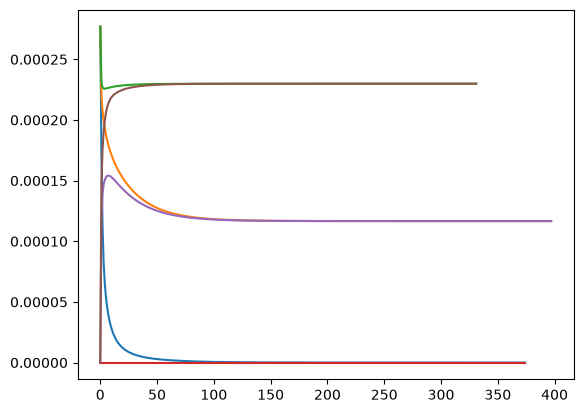

In [650]:
# plt.semilogy(skewT(rT[-1, :]-273.15, grid['p_mid']/100), grid['p_mid']/100, 'r', linewidth=2)
# plt.semilogy(skewT(msT[-1, :]-273.15, grid['p_mid']/100), grid['p_mid']/100, 'b', linewidth=2)
# plt.semilogy(skewT(dryT[-1, :]-273.15, grid['p_mid']/100), grid['p_mid']/100, 'k', linewidth=2)  

'''
    history = {
        "T_surf": [], "T0": [], "OLR": [], "TOA_net": [], # Single level stuff
        "T": [], "F_up": [], "F_down": [], "dTdt_rad": [], "dTdt_conv": [] # Nz stuff
        }
        # T_surf = surface temperature (K)
        # T0 = temperature of lowest atmospheric layer (K)
        # OLR = outgoing longwave radiation at TOA (W/m2)
        # TOA_net = net radiation at TOA (W/m2)
        # T = temperature profile (K) at layer midpoints
        # F_up = upward longwave flux (W/m2) at layer edges
        # F_down = downward longwave flux (W/m2) at layer edges
        # dTdt_rad = radiative heating rate (K/s) at layer midpoints
        # dTdt_conv = convective heating rate (K/s) at layer midpoints
'''

rT = np.array(history_save['radiative']["T"])
drtT = np.array(history_save['dry']["T"])
moistT = np.array(history_save['moist']["T"])

r_t_dT = np.max(abs(np.array(history_save['radiative']["dTdt_rad"])), axis=1)
d_t_dT = np.max(abs(np.array(history_save['dry']["dTdt_rad"])), axis=1)
m_t_dT = np.max(abs(np.array(history_save['moist']["dTdt_rad"])), axis=1)

rc_t_dT = np.max(abs(np.array(history_save['radiative']["dTdt_conv"])), axis=1)
dc_t_dT = np.max(abs(np.array(history_save['dry']["dTdt_conv"])), axis=1)
mc_t_dT = np.max(abs(np.array(history_save['moist']["dTdt_conv"])), axis=1)

plt.figure()
plt.plot(abs(r_t_dT))
plt.plot(abs(d_t_dT))
plt.plot(abs(m_t_dT))

plt.plot(abs(rc_t_dT))
plt.plot(abs(dc_t_dT))
plt.plot(abs(mc_t_dT))

## Deliverable 1 - Time Series

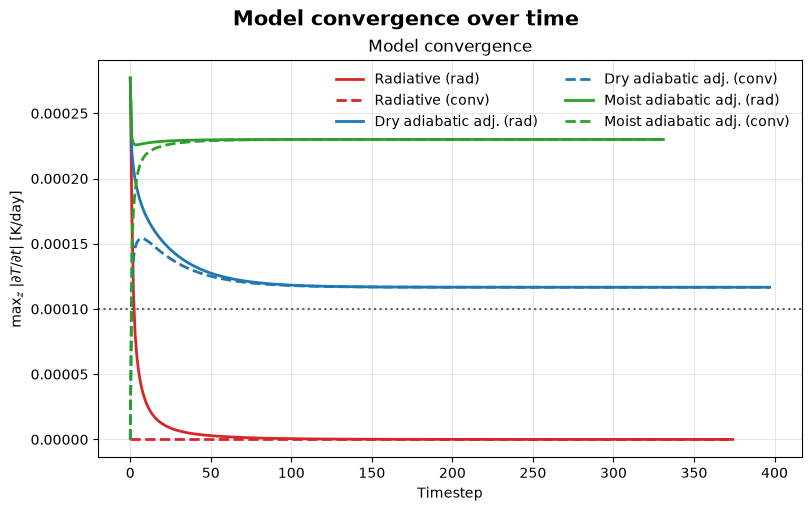

In [648]:
# --- Config -----------------------------------------------------------------
runs = {
    "radiative": {"label": "Radiative",           "color": "#d62728"},
    "dry":       {"label": "Dry adiabatic adj.",  "color": "#1f77b4"},
    "moist":     {"label": "Moist adiabatic adj.", "color": "#2ca02c"},
}
tol = 1e-4  # convergence threshold in K/day (adjust to your units / criterion)

def max_tendency(run, key):
    """Max |dT/dt| over the vertical axis at each timestep."""
    return np.max(np.abs(np.array(history_save[run][key])), axis=1)

# --- Plot -------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for run, style in runs.items():
    ax.plot(max_tendency(run, "dTdt_rad"),  color=style["color"], lw=2, label=f"{style['label']} (rad)")
    ax.plot(max_tendency(run, "dTdt_conv"), color=style["color"], lw=2, ls="--", label=f"{style['label']} (conv)")
ax.axhline(tol, color="k", ls=":", alpha=0.6)
ax.set(xlabel="Timestep", ylabel=r"max$_z$ $|\partial T/\partial t|$ [K/day]", title="Model convergence")
ax.legend(frameon=False, ncol=2)
ax.grid(alpha=0.3)


fig.suptitle("Model convergence over time", fontsize=15, fontweight="bold")
plt.show()

## Deliverable 2 -  Skew T

Text(0, 0.5, 'Pressure(hPa)')

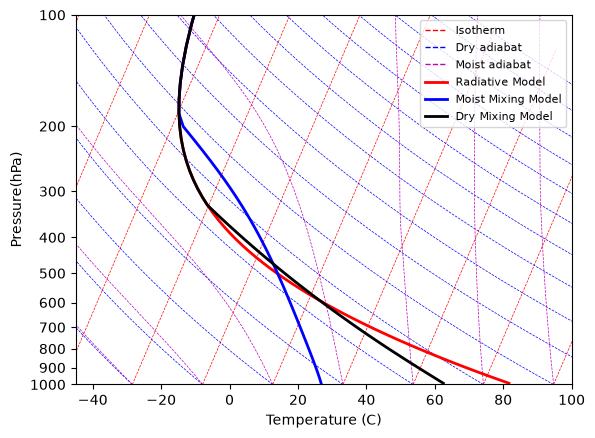

In [637]:

from scipy.integrate import solve_ivp

def skewT(temp, pres, skew=-20): 
    '''
    Skews the temperature axis for a SkewT plot.
    temp: temperature values (deg C)
    pres: pressure values (hPa)
    skew: amount of skew (default of -20)
    '''
    return (temp) + skew * np.log(pres/1000.0)  

Rd = 287
# basically creates an isotherm
def P_from_z(T):  
    P0 = 1000
    z = np.linspace(0,20*1000,500)
    P = P0*np.exp(-9.81*z/Rd/(T+273.15))
    return P 

# initialize the plot
Pct = np.linspace(100,1000,500) 
T = 20 *np.ones_like(Pct)

isot_20_y = P_from_z(20)    
T = 20 *np.ones_like(isot_20_y) 
isot_20_x = skewT(T, isot_20_y)
myarray = np.linspace(-90,300, 20)
plt.figure(1) 
plt.ylim([1000,100])  
# loop over a range of values and plot every isotherm
for i in myarray:
    T = i *np.ones_like(Pct)
    isot_20_y = P_from_z(i)    
    T =  i*np.ones_like(isot_20_y) 
    isot_20_x = skewT(T, isot_20_y) 
    plt.semilogy(isot_20_x,isot_20_y,'r--',linewidth = 0.5)

# create dry adiabat function and integrate. Loop over lots of values and plot them
T0 = 20   
for i in myarray:
    sol = solve_ivp(dry_adiabat, [1000,100], [i],t_eval=np.linspace(1000,100,500) ) 
    skewsol = skewT(sol.y, sol.t) 
    plt.semilogy(skewsol.T,sol.t,'b--',linewidth = 0.5)    

# create moist adiabat function and integrate. Loop over lots of values and plot them

 

for i in myarray:
    sol = solve_ivp(moist_adiabat, [1000,100], [i],t_eval=np.linspace(1000,100,500) ) 
    skewsol = skewT(sol.y, sol.t) 
    plt.semilogy(skewsol.T,sol.t,'m--',linewidth = 0.5)  
plt.xlim([-45,100])
# plt.ylim([1000,100])  


    

from matplotlib.lines import Line2D

# Sounding (after the data arrays)
plt.semilogy(skewT(rT[-1, :]-273.15, grid['p_mid']/100), grid['p_mid']/100, 'r', linewidth=2)
plt.semilogy(skewT(msT[-1, :]-273.15, grid['p_mid']/100), grid['p_mid']/100, 'b', linewidth=2)
plt.semilogy(skewT(dryT[-1, :]-273.15, grid['p_mid']/100), grid['p_mid']/100, 'k', linewidth=2)


# create legend (thanks claude)
legend_items = [
    Line2D([0], [0], color='r', linestyle='--', linewidth=1, label='Isotherm'),
    Line2D([0], [0], color='b', linestyle='--', linewidth=1, label='Dry adiabat'),
    Line2D([0], [0], color='m', linestyle='--', linewidth=1, label='Moist adiabat'),
    Line2D([0], [0], color='r', linestyle='-',  linewidth=2, label='Radiative Model'),
    Line2D([0], [0], color='b', linestyle='-',  linewidth=2, label='Moist Mixing Model'),
    Line2D([0], [0], color='k', linestyle='-',  linewidth=2, label='Dry Mixing Model'),
]
plt.legend(handles=legend_items, loc='upper right', fontsize=8) 

from matplotlib.ticker import ScalarFormatter
ax = plt.gca()
ax.set_yticks([1000, 900, 800, 700, 600,500, 400, 300, 200, 100])
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_minor_formatter(plt.NullFormatter()) 
plt.xlabel('Temperature (C)')
plt.ylabel('Pressure(hPa)')